# PERC1 load model in ANDES: verification tests

This notebook tests the ANDES implementation of the PowerWorld `PERC1` (Power Electronic Reconnecting and Ceasing) load model, `andes/models/dynload/perc1.py`, at three levels.

| Test | Object | Input | Compared with |
|---|---|---|---|
| A. Logic | function `perc1_fracon_step`, the cease/reconnect state machine of the model | prescribed filtered voltage | event times derived by hand; the PowerWorld pseudo-code transcribed in this notebook |
| B. Device | the full model on an infinite bus, `perc1_inf_bus.xlsx` | prescribed terminal voltage and frequency deviation | the block diagram re-implemented in this notebook |
| C. System | two data centers in the IEEE 14-bus system, `ieee14_perc1_fault.xlsx` and `ieee14_perc1_gentrip.xlsx` | bus fault, generator trip | the pseudo-code replayed on the recorded voltage; steady-state relations |

The references of Section 1 are written from the PowerWorld documentation and share no code with the ANDES model. PowerWorld simulation results were not available, so the tests check the implementation against the documented model, not against PowerWorld output.

**Requirements.** ANDES with the `PERC1` model, NumPy, pandas, Matplotlib. Run time about half a minute.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import andes
from andes.models.dynload.perc1 import perc1_fracon_step, perc1_initial_state

andes.config_logger(stream_level=40)  # errors only

HERE = Path.cwd()  # run the notebook from its own folder
CASE_INF = HERE / 'perc1_inf_bus.xlsx'
CASE_FAULT = HERE / 'ieee14_perc1_fault.xlsx'
CASE_TRIP = HERE / 'ieee14_perc1_gentrip.xlsx'
for _f in (CASE_INF, CASE_FAULT, CASE_TRIP):
    assert _f.exists(), f'{_f.name} not found: start the notebook from its own folder'

# generate the numerical code of PERC1 if it is missing or out of date
_probe = andes.System(default_config=True, no_output=True)
if getattr(_probe.PERC1.calls, 'md5', None) != _probe.PERC1.get_md5():
    andes.prepare(models=['PERC1'])
TTOL = _probe.PERC1.config.ttol  # tolerance of the time comparisons in the logic (1e-8 s)
del _probe

SB, FN = 100.0, 60.0  # MVA base, nominal frequency (Hz)
CHECKS = []


def check(cid, desc, ok, detail=''):
    """Record a check and print PASS / FAIL."""
    CHECKS.append(dict(id=cid, description=desc, passed=bool(ok), detail=str(detail)))
    print(f"[{'PASS' if ok else 'FAIL'}] {cid:<4} {desc}" + (f'\n            {detail}' if detail else ''))


print(f'ANDES {andes.__version__}')

ANDES 1.10.0.post114+g31ff8f76b


In [2]:
# Figure style
W2 = 7.16  # figure width (in)
FS = 8.0
C_BLUE, C_ORANGE, C_GREEN, C_MAG, C_GREY, C_INK = '#0072B2', '#D55E00', '#009E73', '#CC79A7', '0.55', '0.15'
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Nimbus Roman', 'TeX Gyre Termes', 'Liberation Serif', 'DejaVu Serif'],
    'font.size': FS, 'mathtext.fontset': 'stix',
    'axes.labelsize': FS, 'axes.titlesize': FS, 'xtick.labelsize': FS, 'ytick.labelsize': FS,
    'legend.fontsize': FS - 1, 'legend.frameon': False, 'legend.handlelength': 1.8,
    'axes.linewidth': 0.8, 'axes.grid': True, 'grid.color': '0.88', 'grid.linewidth': 0.4,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'lines.linewidth': 1.3,
    'figure.dpi': 150, 'figure.facecolor': 'white',
})


def panel(ax, tag, text=''):
    ax.set_title(f'({tag})' + ('  ' + text if text else ''), loc='left', fontsize=FS, pad=3.0)

## 1 References

`CeaseLogic` is the cease/reconnect pseudo-code of the help page, statement by statement. `Perc1Reference` is the block diagram: voltage and frequency filters, voltage washouts, frequency droop with deadband, lead-lags, voltage exponents, current limits and the output lag multiplied by `FracOn`. It is integrated with the trapezoidal rule, the method ANDES uses, so the two can be compared down to the solver tolerance.

In [3]:
MONITOR, CEASED, RAMP = 0, 1, 2  # Mode
T_NONE, T_CEASE, T_DELAY, T_RECON = 0, 1, 2, 3  # TimerActive
MODE = {MONITOR: 'Monitor', CEASED: 'Ceased', RAMP: 'Ramp'}
TIMER = {T_NONE: 'None', T_CEASE: 'Tcease', T_DELAY: 'Tdelay', T_RECON: 'Trecon'}
LOGIC_KEYS = ('Fcease', 'Vcease', 'Tcease', 'Tdelay', 'Frecon', 'Vrecon', 'Trecon', 'Tramp')


class CeaseLogic:
    """PERC1 cease/reconnect pseudo-code for one device, statement by statement.

    A time comparison a >= b is evaluated as a >= b - ttol, so that a timer made of rounded steps
    expires on the intended step.
    """

    def __init__(self, Fcease, Vcease, Tcease, Tdelay, Frecon, Vrecon, Trecon, Tramp, ttol=TTOL):
        self.Fcease, self.Vcease, self.Tcease, self.Tdelay = Fcease, Vcease, Tcease, Tdelay
        self.Frecon, self.Vrecon, self.Trecon, self.Tramp = Frecon, Vrecon, Trecon, Tramp
        self.ttol = ttol
        # "Initialize the following before simulation starts"
        self.FracOn, self.Mode, self.TimerActive, self.Timer, self.TStartRamp = 1.0, MONITOR, T_NONE, 0.0, 0.0

    def ge(self, a, b):
        return a >= b - self.ttol

    def step(self, t, Vfilt):
        """Run the pseudo-code once ("at each time step")."""
        if self.Fcease <= 0:
            return
        f_final = 1 - self.Fcease + self.Frecon * self.Fcease
        if self.Mode == RAMP and self.TimerActive != T_DELAY:  # the ramp is frozen during Tdelay
            if self.ge(t, self.TStartRamp + self.Tramp):
                self.FracOn, self.Mode = f_final, MONITOR
            else:
                self.FracOn = 1 - self.Fcease + self.Frecon * self.Fcease * (t - self.TStartRamp) / self.Tramp
        if self.Mode != CEASED:  # Monitor and Ramp count Tcease and Tdelay the same way
            if self.TimerActive != T_DELAY:
                if Vfilt >= self.Vcease:
                    self.TimerActive = T_NONE
                elif self.TimerActive != T_CEASE:
                    self.Timer, self.TimerActive = t, T_CEASE
            if self.TimerActive == T_CEASE and self.ge(t - self.Timer, self.Tcease):
                self.Timer, self.TimerActive = t, T_DELAY
            if self.TimerActive == T_DELAY and self.ge(t - self.Timer, self.Tdelay):
                self.TimerActive, self.Mode, self.FracOn = T_NONE, CEASED, 1 - self.Fcease
        else:
            if Vfilt < self.Vrecon:
                self.TimerActive = T_NONE
            elif self.TimerActive != T_RECON:
                self.Timer, self.TimerActive = t, T_RECON
            if self.TimerActive == T_RECON and self.ge(t - self.Timer, self.Trecon):
                self.TimerActive = T_NONE
                if self.Tramp == 0:  # no ramp: jump back
                    self.Mode, self.FracOn = MONITOR, f_final
                else:
                    self.Mode, self.TStartRamp = RAMP, t

    def state(self):
        return (self.Mode, self.TimerActive, self.Timer, self.TStartRamp, self.FracOn)

In [4]:
# PowerWorld default parameters of PERC1
DEFAULTS = dict(
    Lfm=0.80, QPratio=0.66, Dbfl=0.0, Dbfh=0.0, Kdroop=0.0, Kvp=0.0, Tvp=0.10, Kvq=0.0, Tvq=0.10,
    Tap=0.0, Tbp=0.0, Taq=0.0, Tbq=0.0, nP=0.0, nQ=1.0, Ipmax=1.0, Ipmin=0.0, Iqmax=0.66, Iqmin=-0.66,
    Fcease=1.0, Vcease=0.50, Tcease=0.01, Tdelay=0.0, Vrecon=0.60, Trecon=0.05, Tramp=1.0, Frecon=1.0,
    Tt=0.02, Tv=0.02, Tf=0.02,
)
STATES = ('xPc', 'xQc', 'xdP', 'xdQ', 'wfilt', 'Vfilt', 'Ip', 'Iq')  # block-diagram states 1-8


class Perc1Reference:
    """PERC1 block diagram driven by a prescribed terminal voltage V(t) and frequency deviation dw(t).

    Per-unit values are on MBase = MWinit / Lfm. Host rules: Tt >= 4 x time step; frequency input ignored
    below 0.7 pu; constant impedance if V0 < Vcease, V0 < 0.5 pu or MWinit <= 0; Vfilt guarded at 0.001 pu.
    """

    def __init__(self, prm, V0, P0, Q0, h):
        self.p = p = dict(DEFAULTS, **prm)
        self.V0, self.P0, self.Q0 = V0, P0, Q0
        self.fallback = V0 < p['Vcease'] or V0 < 0.5 or P0 <= 0
        lfm = 0.8 if p['Lfm'] < 0.001 else p['Lfm']
        self.MBase = 0.0 if self.fallback else P0 / lfm
        self.Pinit = 0.0 if self.fallback else lfm  # MWinit / MBase
        self.Qinit = 0.0 if self.fallback else p['QPratio'] * lfm  # MvarInit = QPratio x MWinit
        # stand-alone model: the rest of the initial Mvar is a constant current added after the limiter
        self.Iqextra = 0.0 if self.fallback else (Q0 - p['QPratio'] * P0) / (self.MBase * V0)
        self.Tt = p['Tt'] if p['Tt'] >= 4 * h * (1 - 5e-4) else 4 * h

    def algebraic(self, x, V):
        """All block outputs for the state vector x and the inputs."""
        p = self.p
        xPc, xQc, xdP, xdQ, wfilt, Vfilt, Ip, Iq = x
        dP = p['Kvp'] * (V - xdP) / p['Tvp'] if p['Tvp'] > 0 else 0.0  # washouts on the raw voltage
        dQ = p['Kvq'] * (V - xdQ) / p['Tvq'] if p['Tvq'] > 0 else 0.0
        db = wfilt - p['Dbfh'] if wfilt > p['Dbfh'] else (wfilt - p['Dbfl'] if wfilt < p['Dbfl'] else 0.0)
        Pin = self.Pinit + dP + p['Kdroop'] * db
        Qin = self.Qinit + dQ
        Pctrl = xPc + p['Tap'] / p['Tbp'] * (Pin - xPc) if p['Tbp'] > 0 else Pin  # lead-lags
        Qctrl = xQc + p['Taq'] / p['Tbq'] * (Qin - xQc) if p['Tbq'] > 0 else Qin
        Vg = max(Vfilt, 1e-3)
        Ipcmd = Pctrl * (Vg / self.V0) ** p['nP'] / Vg  # voltage exponent, then power -> current
        Iqcmd = Qctrl * (Vg / self.V0) ** p['nQ'] / Vg
        Ipv = min(max(Ipcmd, p['Ipmin']), p['Ipmax'])
        Iqv = min(max(Iqcmd, p['Iqmin']), p['Iqmax'])
        if self.fallback:
            Pmw, Qmvar = self.P0 * (V / self.V0) ** 2, self.Q0 * (V / self.V0) ** 2
        else:
            Pmw, Qmvar = self.MBase * V * Ip, self.MBase * V * Iq
        return dict(Vfilt=Vfilt, wfilt=wfilt, dP=dP, dQ=dQ, Pin=Pin, Qin=Qin, Pctrl=Pctrl, Qctrl=Qctrl,
                    Ipcmd=Ipcmd, Iqcmd=Iqcmd, Ipv=Ipv, Iqv=Iqv, Ip=Ip, Iq=Iq, Pmw=Pmw, Qmvar=Qmvar)

    def rhs(self, x, V, dw, FracOn):
        """Time derivatives of the eight states (zero for bypassed blocks)."""
        p, s = self.p, self.algebraic(x, V)
        xPc, xQc, xdP, xdQ, wfilt, Vfilt, Ip, Iq = x
        dx = np.zeros(8)
        if p['Tbp'] > 0:
            dx[0] = (s['Pin'] - xPc) / p['Tbp']
        if p['Tbq'] > 0:
            dx[1] = (s['Qin'] - xQc) / p['Tbq']
        if p['Tvp'] > 0:
            dx[2] = (V - xdP) / p['Tvp']
        if p['Tvq'] > 0:
            dx[3] = (V - xdQ) / p['Tvq']
        dx[4] = ((dw if V >= 0.7 else 0.0) - wfilt) / p['Tf']
        dx[5] = (V - Vfilt) / p['Tv']
        dx[6] = (FracOn * s['Ipv'] - Ip) / self.Tt  # output lags, FracOn multiplies their inputs
        dx[7] = (FracOn * (s['Iqv'] + self.Iqextra) - Iq) / self.Tt
        return dx

    def trap_step(self, x0, f0, h, V1, dw1, FracOn):
        """One step of the implicit trapezoidal rule (Newton, numerical Jacobian)."""
        x = x0 + h * f0
        for _ in range(50):
            f1 = self.rhs(x, V1, dw1, FracOn)
            G = x - x0 - 0.5 * h * (f0 + f1)
            J = np.eye(8)
            for j in range(8):
                xp = x.copy()
                d = 1e-7 * max(1.0, abs(x[j]))
                xp[j] += d
                J[:, j] -= 0.5 * h * (self.rhs(xp, V1, dw1, FracOn) - f1) / d
            dx = np.linalg.solve(J, -G)
            x = x + dx
            if np.max(np.abs(dx)) < 1e-13:
                break
        return x

    def simulate(self, t, V, dw):
        """Integrate on the grid t with the inputs V, dw given on the grid; the logic runs once per point
        and the new FracOn is held during the following step."""
        p = self.p
        logic = CeaseLogic(*(p[k] for k in LOGIC_KEYS))
        x = np.array([self.Pinit, self.Qinit, self.V0, self.V0, 0.0, self.V0, 0.0, 0.0])
        s0 = self.algebraic(x, self.V0)
        x[6], x[7] = s0['Ipv'], s0['Iqv'] + self.Iqextra
        keys = list(s0) + ['FracOn', 'Mode', 'TimerActive']
        out = {k: np.zeros(len(t)) for k in keys}
        for n in range(len(t)):
            if n > 0 and not self.fallback:
                logic.step(t[n], x[5])
            s = self.algebraic(x, V[n])
            s.update(FracOn=logic.FracOn, Mode=logic.Mode, TimerActive=logic.TimerActive)
            for k in keys:
                out[k][n] = s[k]
            if n < len(t) - 1:
                f0 = self.rhs(x, V[n], dw[n], logic.FracOn)
                x = self.trap_step(x, f0, t[n + 1] - t[n], V[n + 1], dw[n + 1], logic.FracOn)
        return out

## 2 Test A: cease/reconnect logic

The model function and `CeaseLogic` receive the same samples of the filtered voltage (step 1 ms). The parameters are those of the PowerWorld FracOn example: `Fcease` = 0.75 and `Frecon` = 0.60, so `FracOn` goes 1.00 → 0.25 → 0.70. Thresholds `Vcease` = 0.80 and `Vrecon` = 0.90 pu; timers `Tcease` = 0.10 s, `Tdelay` = 0.05 s, `Trecon` = 0.20 s, `Tramp` = 1.0 s.

| Scenario | Prescribed `Vfilt` | Expected |
|---|---|---|
| A1 | 0.70 pu during 1.0–1.5 s and 4.0–4.5 s; 0.75 pu during 3.00–3.05 s | cease at 1.15 s, ramp 1.70–2.70 s; the 50 ms dip changes nothing; second cycle identical |
| A2 | 0.70 pu during 1.00–1.12 s | the voltage is back before `Tdelay` ends, the load still ceases at 1.15 s; `Trecon` starts one step later |
| A3 | 0.85 pu during 1.6–1.8 s, while `Trecon` is counting | `Trecon` restarts at 1.8 s, ramp from 2.0 s |
| A4 | second dip at 2.0 s, during the ramp | the ramp continues during `Tcease`, `FracOn` is frozen at 0.43 during `Tdelay`, then drops to 0.25 |
| A5 | dip of A1 | `Tramp` = 0, `Frecon` > 1 and `Fcease` = 0 |
| A6 | 300 random parameter sets and voltage profiles | model function equal to the pseudo-code at every step |

In [5]:
# parameters of the PowerWorld FracOn example: 75 % ceases, 60 % of it comes back
LOGIC = dict(Fcease=0.75, Vcease=0.80, Tcease=0.10, Tdelay=0.05, Frecon=0.60, Vrecon=0.90, Trecon=0.20, Tramp=1.00)
F_CEASED = 1 - LOGIC['Fcease']  # 0.25
F_FINAL = 1 - LOGIC['Fcease'] + LOGIC['Fcease'] * LOGIC['Frecon']  # 0.70
H_LOGIC = 0.001  # sampling step (s)


def piecewise(segments, t):
    """Right-continuous piecewise-constant signal: segments = [(start time, value), ...]."""
    starts = np.array([s for s, _ in segments])
    values = np.array([v for _, v in segments])
    return values[np.searchsorted(starts, t + 1e-9, side='right') - 1]


def run_logic(prm, t, v):
    """Drive the model function and the reference with the same Vfilt samples.
    Returns two arrays (n, 5): Mode, TimerActive, Timer, TStartRamp, FracOn."""
    st, ref = perc1_initial_state(1), CeaseLogic(**prm)
    M, R = np.zeros((len(t), 5)), np.zeros((len(t), 5))
    for k in range(len(t)):
        if k > 0:  # the logic runs once per step, after t = 0
            st = perc1_fracon_step(st, t[k], v[k : k + 1], *(prm[x] for x in LOGIC_KEYS), ttol=TTOL)
            ref.step(t[k], v[k])
        M[k] = st.mode[0], st.tact[0], st.timer[0], st.tsr[0], st.fon[0]
        R[k] = ref.state()
    return M, R


def transitions(t, mode, tact):
    """Changes of Mode and TimerActive as (time, variable, new value)."""
    ev = []
    for k in range(1, len(t)):
        if mode[k] != mode[k - 1]:
            ev.append((round(float(t[k]), 6), 'Mode', MODE[int(mode[k])]))
        if tact[k] != tact[k - 1]:
            ev.append((round(float(t[k]), 6), 'Timer', TIMER[int(tact[k])]))
    return ev


# scenario: Vfilt segments, expected events (time, variable, new value), duration
SCEN_A = {
    'A1': dict(
        title='FracOn example: two dips and one dip shorter than Tcease',
        V=[(0, 1.0), (1.0, 0.70), (1.5, 1.0), (3.0, 0.75), (3.05, 1.0), (4.0, 0.70), (4.5, 1.0)],
        tf=7.0,
        expected=[
            (1.000, 'Timer', 'Tcease'), (1.100, 'Timer', 'Tdelay'), (1.150, 'Mode', 'Ceased'),
            (1.500, 'Timer', 'Trecon'), (1.700, 'Mode', 'Ramp'), (2.700, 'Mode', 'Monitor'),
            (3.000, 'Timer', 'Tcease'), (3.050, 'Timer', 'None'),
            (4.000, 'Timer', 'Tcease'), (4.100, 'Timer', 'Tdelay'), (4.150, 'Mode', 'Ceased'),
            (4.500, 'Timer', 'Trecon'), (4.700, 'Mode', 'Ramp'), (5.700, 'Mode', 'Monitor'),
        ],
    ),
    'A2': dict(
        title='recovery during Tdelay: the cease is not cancelled',
        V=[(0, 1.0), (1.0, 0.70), (1.12, 1.0)],
        tf=3.0,
        expected=[
            (1.100, 'Timer', 'Tdelay'), (1.150, 'Mode', 'Ceased'), (1.151, 'Timer', 'Trecon'),
            (1.351, 'Mode', 'Ramp'), (2.351, 'Mode', 'Monitor'),
        ],
    ),
    'A3': dict(
        title='Trecon interrupted: voltage between Vcease and Vrecon restarts the timer',
        V=[(0, 1.0), (1.0, 0.70), (1.5, 1.0), (1.6, 0.85), (1.8, 1.0)],
        tf=3.5,
        expected=[
            (1.150, 'Mode', 'Ceased'), (1.500, 'Timer', 'Trecon'), (1.600, 'Timer', 'None'),
            (1.800, 'Timer', 'Trecon'), (2.000, 'Mode', 'Ramp'), (3.000, 'Mode', 'Monitor'),
        ],
    ),
    'A4': dict(
        title='dip during the ramp: FracOn frozen during Tdelay, then ceased again',
        V=[(0, 1.0), (1.0, 0.70), (1.5, 1.0), (2.0, 0.70), (2.12, 0.85), (2.3, 1.0), (3.0, 0.75), (3.05, 1.0)],
        tf=4.0,
        expected=[
            (1.150, 'Mode', 'Ceased'), (1.700, 'Mode', 'Ramp'), (2.000, 'Timer', 'Tcease'),
            (2.100, 'Timer', 'Tdelay'), (2.150, 'Mode', 'Ceased'), (2.300, 'Timer', 'Trecon'),
            (2.500, 'Mode', 'Ramp'), (3.000, 'Timer', 'Tcease'), (3.050, 'Timer', 'None'),
            (3.500, 'Mode', 'Monitor'),
        ],
    ),
}

RES_A = {}
for key, sc in SCEN_A.items():
    t = np.arange(int(round(sc['tf'] / H_LOGIC)) + 1) * H_LOGIC
    v = piecewise(sc['V'], t)
    M, R = run_logic(LOGIC, t, v)
    RES_A[key] = dict(t=t, v=v, M=M, R=R)
    ev = transitions(t, M[:, 0], M[:, 1])
    missing = [e for e in sc['expected'] if e not in ev]
    same = np.array_equal(M[:, :2], R[:, :2]) and np.abs(M[:, 2:] - R[:, 2:]).max() < 1e-12
    check(
        key,
        sc['title'],
        same and not missing and abs(M[-1, 4] - F_FINAL) < 1e-12,
        f"{len(sc['expected'])} expected events found, every step equal to the reference, final FracOn {M[-1, 4]:.2f}",
    )

# event table of the FracOn example
ev = transitions(RES_A['A1']['t'], RES_A['A1']['M'][:, 0], RES_A['A1']['M'][:, 1])
tab = pd.DataFrame(SCEN_A['A1']['expected'], columns=['t_expected', 'variable', 'new value'])
tab['t_model'] = [
    next((e[0] for e in ev if e[1:] == x[1:] and abs(e[0] - x[0]) < 0.5), np.nan) for x in SCEN_A['A1']['expected']
]
print('\nA1, expected and simulated event times (s):')
print(tab.to_string(index=False))

[PASS] A1   FracOn example: two dips and one dip shorter than Tcease
            14 expected events found, every step equal to the reference, final FracOn 0.70
[PASS] A2   recovery during Tdelay: the cease is not cancelled
            5 expected events found, every step equal to the reference, final FracOn 0.70
[PASS] A3   Trecon interrupted: voltage between Vcease and Vrecon restarts the timer
            6 expected events found, every step equal to the reference, final FracOn 0.70
[PASS] A4   dip during the ramp: FracOn frozen during Tdelay, then ceased again
            10 expected events found, every step equal to the reference, final FracOn 0.70

A1, expected and simulated event times (s):
 t_expected variable new value  t_model
       1.00    Timer    Tcease     1.00
       1.10    Timer    Tdelay     1.10
       1.15     Mode    Ceased     1.15
       1.50    Timer    Trecon     1.50
       1.70     Mode      Ramp     1.70
       2.70     Mode   Monitor     2.70
       3.00    T

In [6]:
# A4 in detail: the ramp continues during Tcease, is frozen during Tdelay, then FracOn drops to 1 - Fcease
def k(x):
    return int(round(x / H_LOGIC))  # sample index of a time


t, M = RES_A['A4']['t'], RES_A['A4']['M']
slope = LOGIC['Frecon'] * LOGIC['Fcease'] / LOGIC['Tramp']  # 0.45 per second
check(
    'A4a',
    'ramp continues during Tcease and is frozen at its value when Tdelay starts',
    abs(M[k(2.0), 4] - (F_CEASED + slope * 0.30)) < 1e-12
    and np.abs(M[k(2.1) : k(2.15), 4] - (F_CEASED + slope * 0.40)).max() < 1e-12
    and np.all(M[k(2.1) : k(2.15), 0] == RAMP),
    f'FracOn {M[k(2.0), 4]:.3f} at 2.00 s, {M[k(2.1), 4]:.3f} from 2.10 to 2.15 s',
)
check(
    'A4b',
    'Tdelay expires: Ramp -> Ceased directly, FracOn = 1 - Fcease',
    M[k(2.15) - 1, 0] == RAMP and M[k(2.15), 0] == CEASED and M[k(2.15), 4] == F_CEASED,
)

# special parameter values, same dip as A1
t = np.arange(4001) * H_LOGIC
v = piecewise([(0, 1.0), (1.0, 0.70), (1.5, 1.0)], t)
M0, _ = run_logic(dict(LOGIC, Tramp=0.0), t, v)
M1, _ = run_logic(dict(LOGIC, Frecon=1.2), t, v)
M2, _ = run_logic(dict(LOGIC, Fcease=0.0), t, v)
check(
    'A5',
    'Tramp = 0: jump without Ramp mode; Frecon > 1: final FracOn > 1; Fcease = 0: logic off',
    not np.any(M0[:, 0] == RAMP)
    and M0[k(1.7) - 1, 4] == F_CEASED
    and abs(M0[k(1.7), 4] - F_FINAL) < 1e-12
    and abs(M1[-1, 4] - (0.25 + 1.2 * 0.75)) < 1e-12
    and np.all(M2[:, 4] == 1.0),
    f'final FracOn {M0[-1, 4]:.2f} / {M1[-1, 4]:.2f} / {M2[-1, 4]:.2f}',
)

[PASS] A4a  ramp continues during Tcease and is frozen at its value when Tdelay starts
            FracOn 0.385 at 2.00 s, 0.430 from 2.10 to 2.15 s
[PASS] A4b  Tdelay expires: Ramp -> Ceased directly, FracOn = 1 - Fcease
[PASS] A5   Tramp = 0: jump without Ramp mode; Frecon > 1: final FracOn > 1; Fcease = 0: logic off
            final FracOn 0.70 / 1.15 / 1.00


In [7]:
# A6: random parameters and random voltage profiles, all devices in one vectorized call of the model function
rng = np.random.default_rng(1)
N, H_RND, T_RND = 300, 0.01, 10.0
t = np.arange(int(round(T_RND / H_RND)) + 1) * H_RND
P = dict(
    Fcease=np.where(rng.random(N) < 0.1, 0.0, rng.uniform(0.05, 1.0, N)),
    Vcease=rng.uniform(0.4, 0.9, N),
    Tcease=rng.uniform(0.0, 0.3, N),
    Tdelay=np.where(rng.random(N) < 0.3, 0.0, rng.uniform(0.0, 0.3, N)),
    Frecon=rng.uniform(0.0, 1.5, N),
    Trecon=rng.uniform(0.0, 0.5, N),
    Tramp=np.where(rng.random(N) < 0.2, 0.0, rng.uniform(0.05, 2.0, N)),
)
P['Vrecon'] = P['Vcease'] + rng.uniform(0.0, 0.2, N)
V = np.empty((len(t), N))
for j in range(N):  # random levels held for random times
    starts = np.cumsum(rng.uniform(0.02, 1.0, 40))
    V[:, j] = piecewise(list(zip(np.r_[0.0, starts], np.r_[1.0, rng.uniform(0.2, 1.1, 40)])), t)

st = perc1_initial_state(N)
FON, MODE_N = np.ones((len(t), N)), np.zeros((len(t), N))
for i in range(1, len(t)):
    st = perc1_fracon_step(st, t[i], V[i], *(P[x] for x in LOGIC_KEYS), ttol=TTOL)
    FON[i], MODE_N[i] = st.fon, st.mode
err, n_cease = 0.0, 0
for j in range(N):
    ref = CeaseLogic(*(P[x][j] for x in LOGIC_KEYS))
    for i in range(1, len(t)):
        ref.step(t[i], V[i, j])
        err = max(err, abs(ref.FracOn - FON[i, j]), abs(ref.Mode - MODE_N[i, j]))
    n_cease += int(np.any(MODE_N[:, j] == CEASED))
check(
    'A6',
    f'{N} random parameter sets and voltage profiles: model function equals the reference at every step',
    err < 1e-12,
    f'max difference {err:.1e}; {n_cease} of {N} devices ceased at least once',
)

[PASS] A6   300 random parameter sets and voltage profiles: model function equals the reference at every step
            max difference 4.4e-16; 269 of 300 devices ceased at least once


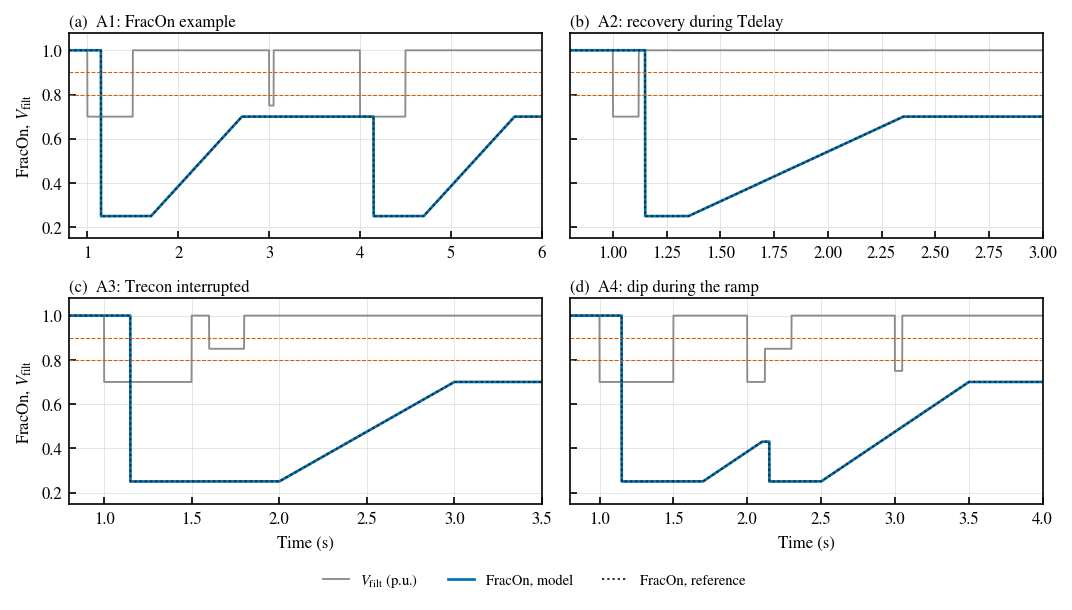

Fig. 1.  Logic level. Prescribed filtered voltage (grey), FracOn of the model function (blue) and of the reference (dotted). Dashed lines: Vcease = 0.80 and Vrecon = 0.90 pu.


In [8]:
# Fig. 1: FracOn of the four scenarios, model function and reference
fig, axs = plt.subplots(2, 2, figsize=(W2, 4.0), sharey=True)
for ax, (key, sc), tag in zip(axs.ravel(), SCEN_A.items(), 'abcd'):
    r = RES_A[key]
    ax.plot(r['t'], r['v'], color=C_GREY, lw=0.9, label='$V_\\mathrm{filt}$ (p.u.)')
    ax.plot(r['t'], r['M'][:, 4], color=C_BLUE, label='FracOn, model')
    ax.plot(r['t'], r['R'][:, 4], color=C_INK, lw=0.9, ls=(0, (1.2, 1.6)), label='FracOn, reference')
    for lvl in (LOGIC['Vcease'], LOGIC['Vrecon']):
        ax.axhline(lvl, color=C_ORANGE, lw=0.5, ls='--')
    ax.set_xlim(0.8, min(r['t'][-1], 6.0))
    ax.set_ylim(0.15, 1.08)
    panel(ax, tag, f'{key}: {sc["title"].split(":")[0]}')
for ax in axs[1]:
    ax.set_xlabel('Time (s)')
for ax in axs[:, 0]:
    ax.set_ylabel('FracOn, $V_\\mathrm{filt}$')
h, lab = axs[0, 0].get_legend_handles_labels()
fig.legend(h, lab, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.045, 1, 1))
plt.show()
print('Fig. 1.  Logic level. Prescribed filtered voltage (grey), FracOn of the model function (blue) and of the '
      'reference (dotted). Dashed lines: Vcease = 0.80 and Vrecon = 0.90 pu.')

## 3 Test B: device on an infinite bus

`perc1_inf_bus.xlsx` has a 50 MW, 20 Mvar load on the slack bus, replaced by PERC1. Before every step the slack voltage and the external frequency deviation `dwext` of the model are set to prescribed values, so the model sees a known $V(t)$ and $\Delta\omega(t)$. The reference runs on the same time grid (step 1/120 s) with the recorded terminal voltage.

Tolerances: 1e-7 pu on the model base for the block outputs, 1e-5 MW for $P$ and $Q$, identical `Mode`, `TimerActive` and `FracOn`.

In [9]:
CONT = ['Vfilt', 'wfilt', 'dP', 'dQ', 'Pin', 'Qin', 'Pctrl', 'Qctrl', 'Ipcmd', 'Iqcmd', 'Ipv', 'Iqv', 'Ip', 'Iq']
OUTPUTS = CONT + ['Pmw', 'Qmvar', 'FracOn', 'Mode', 'TimerActive']
H_DEV = 1 / 120  # half a cycle


def run_device(prm, V, dw=None, tf=3.0, V0=1.0, P0=50.0, Q0=20.0):
    """PERC1 on the infinite bus with prescribed V(t) and dw(t) (functions of time). Returns (system, signals)."""
    ss = andes.load(str(CASE_INF), setup=False, no_output=True, default_config=True)
    ss.Bus.v0.v[:] = [V0] * ss.Bus.n  # parameters are plain lists before setup()
    ss.Slack.v0.v[0] = V0
    ss.PQ.p0.v[0] = ss.Slack.p0.v[0] = P0 / SB
    ss.PQ.q0.v[0] = ss.Slack.q0.v[0] = Q0 / SB
    for key, val in prm.items():
        ss.PERC1.__dict__[key].v[0] = val
    ss.setup()
    ss.PFlow.config.tol = 1e-12
    ss.PFlow.run()
    ss.TDS.config.tstep, ss.TDS.config.tf, ss.TDS.config.tol = H_DEV, tf, 1e-9
    ss.TDS.config.honest, ss.TDS.config.no_tqdm = 1, 1

    def set_inputs(t, system):  # called by TDS before every step
        system.Slack.v0.v[:] = V(float(t))
        if dw is not None:
            system.PERC1.dwext.v[:] = dw(float(t))

    ss.TDS.callpert = set_inputs
    ss.TDS.run(no_summary=True)
    ss.dae.ts.unpack()
    m, ts = ss.PERC1, ss.dae.ts
    sig = dict(t=np.array(ts.t), V=np.array(ts.y[:, m.v.a[0]]))
    for key in OUTPUTS:
        var = m.__dict__[key]
        sig[key] = np.array((ts.x if var.v_code == 'x' else ts.y)[:, var.a[0]])
    return ss, sig


def reference_for(ss, sig, prm, dw=None):
    """The reference on the ANDES time grid, driven by the recorded terminal voltage."""
    m = ss.PERC1
    ref = Perc1Reference(prm, float(m.v0.v[0]), float(m.p0.v[0]) * SB, float(m.q0.v[0]) * SB, H_DEV)
    dw_t = np.zeros_like(sig['t']) if dw is None else np.array([dw(x) for x in sig['t']])
    return ref.simulate(sig['t'], sig['V'], dw_t)


def steps(*pairs, v0=1.0):
    """V(t) that starts at v0 and takes the given values from the given times on."""
    return lambda t: ([v0] + [val for ts, val in pairs if t >= ts - 1e-9])[-1]

In [10]:
# B1: initialization. The PQ load is taken over at its power-flow values.
PRM_B1 = dict(QPratio=0.3, Lfm=0.7)
ss, a = run_device(PRM_B1, steps(v0=0.97), tf=0.5, V0=0.97, P0=80.0, Q0=30.0)
m = ss.PERC1
MB = 80.0 / 0.7
exp = dict(Pmw=80.0, Qmvar=30.0, MBase=MB, Ip=0.7 / 0.97, Iqextra=(30.0 - 0.3 * 80.0) / (MB * 0.97))
got = dict(Pmw=a['Pmw'][0], Qmvar=a['Qmvar'][0], MBase=m.MB.v[0], Ip=a['Ip'][0], Iqextra=m.Iqx.v[0])
print(pd.DataFrame(dict(expected=exp, ANDES=got)).to_string(float_format=lambda x: f'{x:.6f}'))
check('B1', 'initialization: P, Q = power-flow load; MBase = P0 / Lfm; Ip = Lfm / V0; Iqextra carries Q0 - QPratio P0',
      ss.TDS.test_ok and ss.PQ.u.v[0] == 0 and all(abs(got[k] - exp[k]) < 1e-8 for k in exp)
      and np.abs(a['Pmw'] - 80.0).max() < 1e-6 and np.abs(a['Qmvar'] - 30.0).max() < 1e-6,
      'the PQ is switched off and the model stays at the initial point without a disturbance')

          expected      ANDES
Pmw      80.000000  80.000000
Qmvar    30.000000  30.000000
MBase   114.285714 114.285714
Ip        0.721649   0.721649
Iqextra   0.054124   0.054124
[PASS] B1   initialization: P, Q = power-flow load; MBase = P0 / Lfm; Ip = Lfm / V0; Iqextra carries Q0 - QPratio P0
            the PQ is switched off and the model stays at the initial point without a disturbance


In [11]:
# B2: dynamic response against the reference
def wave(t):
    """Dip to 0.3 pu for 0.2 s, later a 1.5 Hz voltage oscillation."""
    if 0.5 <= t < 0.7:
        return 0.3
    return 1.0 + 0.02 * np.sin(2 * np.pi * 1.5 * t) if t >= 1.2 else 1.0


SCEN_B = {
    'defaults': dict(title='default parameters, dip to 0.3 pu for 0.2 s', prm={}, V=steps((0.5, 0.3), (0.7, 1.0))),
    'all blocks': dict(
        title='washouts, lead-lags, droop with deadband, exponents, Tdelay',
        prm=dict(Fcease=0.75, Frecon=0.6, Kvp=0.3, Kvq=0.2, Tap=0.05, Tbp=0.1, Taq=0.02, Tbq=0.08,
                 nP=0.5, nQ=1.7, Kdroop=2.0, Dbfl=-0.001, Dbfh=0.0005, Tdelay=0.02),
        V=wave, dw=lambda t: 0.004 * np.sin(2 * np.pi * 0.8 * t),
    ),
    'repeated': dict(
        title='Frecon = 1.2, dips during the ramp',
        prm=dict(Fcease=0.8, Frecon=1.2, Tramp=0.5, Tdelay=0.03), tf=4.0,
        V=steps((0.3, 0.2), (0.5, 1.0), (0.75, 0.0), (0.775, 1.0), (1.8, 0.3), (2.3, 1.0), (2.55, 0.4), (2.62, 1.0)),
    ),
    'deep dip': dict(title='dip to 0.0005 pu (Vfilt guard)', prm=dict(nP=0.5, nQ=2.0, Fcease=0.5),
                     V=steps((0.5, 0.0005), (0.9, 1.0))),
    'limits': dict(title='constant power, Ipmax and Iqmax reached at 0.75 pu',
                   prm=dict(nP=0.0, nQ=0.0, QPratio=0.4, Iqmax=0.42), V=steps((0.5, 0.75), (1.0, 1.0))),
    'fallback': dict(title='V0 = 0.45 pu: constant impedance', prm=dict(Vcease=0.3, Vrecon=0.4), V0=0.45,
                     V=steps((0.5, 0.2), (0.7, 0.45), v0=0.45)),
}

rows, RES_B = [], {}
for key, sc in SCEN_B.items():
    ss, a = run_device(sc['prm'], sc['V'], sc.get('dw'), tf=sc.get('tf', 3.0), V0=sc.get('V0', 1.0))
    r = reference_for(ss, a, sc['prm'], sc.get('dw'))
    RES_B[key] = (a, r)
    e_pu = max(float(np.max(np.abs(a[k] - r[k]) / np.maximum(1.0, np.abs(r[k])))) for k in CONT)
    e_mw = max(float(np.abs(a[k] - r[k]).max()) for k in ('Pmw', 'Qmvar'))
    same = (
        all(np.array_equal(a[k], r[k]) for k in ('Mode', 'TimerActive'))
        and np.abs(a['FracOn'] - r['FracOn']).max() < 1e-12
    )
    rows.append(dict(scenario=key, description=sc['title'], mode_changes=int(np.count_nonzero(np.diff(a['Mode']))),
                     max_err_pu=e_pu, max_err_MW=e_mw, logic_identical=same, completed=ss.exit_code == 0))
TAB_B = pd.DataFrame(rows)
print(TAB_B.to_string(index=False, float_format=lambda x: f'{x:.1e}'))
check(
    'B2',
    'device response equals the reference in all six scenarios',
    bool(
        TAB_B.completed.all()
        and TAB_B.logic_identical.all()
        and (TAB_B.max_err_pu < 1e-7).all()
        and (TAB_B.max_err_MW < 1e-5).all()
    ),
    f'largest error {TAB_B.max_err_pu.max():.1e} pu on MBase, {TAB_B.max_err_MW.max():.1e} MW / Mvar; '
    'logic outputs identical',
)
a = RES_B['limits'][0]
check(
    'B3',
    'current limits: Ipv = Ipmax and Iqv = Iqmax during the 0.75 pu dip',
    abs(a['Ipv'].max() - 1.0) < 1e-12
    and abs(a['Iqv'].max() - 0.42) < 1e-12
    and a['Ipcmd'].max() > 1.0
    and a['Iqcmd'].max() > 0.42,
    f"commands {a['Ipcmd'].max():.3f} / {a['Iqcmd'].max():.3f} pu "
    f"limited to {a['Ipv'].max():.2f} / {a['Iqv'].max():.2f} pu",
)

  scenario                                                 description  mode_changes  max_err_pu  max_err_MW  logic_identical  completed
  defaults                 default parameters, dip to 0.3 pu for 0.2 s             3     3.5e-10     2.2e-08             True       True
all blocks washouts, lead-lags, droop with deadband, exponents, Tdelay             3     2.4e-10     2.8e-09             True       True
  repeated                          Frecon = 1.2, dips during the ramp             8     5.2e-10     2.6e-08             True       True
  deep dip                              dip to 0.0005 pu (Vfilt guard)             3     1.4e-08     3.0e-08             True       True
    limits          constant power, Ipmax and Iqmax reached at 0.75 pu             0     5.1e-10     3.2e-08             True       True
  fallback                            V0 = 0.45 pu: constant impedance             0     2.6e-10     6.3e-09             True       True
[PASS] B2   device response equals the re

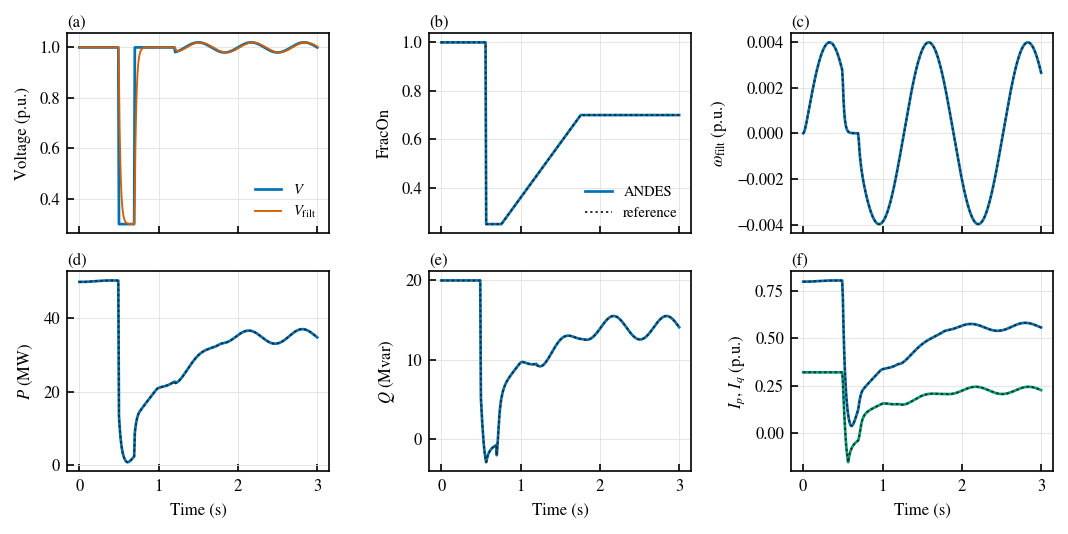

Fig. 2.  Device level, scenario "all blocks": voltage dip to 0.3 pu, voltage oscillation and frequency deviation. ANDES (solid) and the reference (dotted).


In [12]:
# Fig. 2: the "all blocks" scenario, ANDES and reference
a, r = RES_B['all blocks']
fig, axs = plt.subplots(2, 3, figsize=(W2, 3.6), sharex=True)
spec = [('V', 'Voltage (p.u.)'), ('FracOn', 'FracOn'), ('wfilt', '$\\omega_\\mathrm{filt}$ (p.u.)'),
        ('Pmw', '$P$ (MW)'), ('Qmvar', '$Q$ (Mvar)'), ('Ip', '$I_p$, $I_q$ (p.u.)')]
for ax, (key, lab), tag in zip(axs.ravel(), spec, 'abcdef'):
    ax.plot(a['t'], a[key], color=C_BLUE, label='ANDES')
    if key != 'V':
        ax.plot(a['t'], r[key], color=C_INK, lw=0.9, ls=(0, (1.2, 1.6)), label='reference')
    if key == 'V':
        ax.plot(a['t'], a['Vfilt'], color=C_ORANGE, lw=0.9, label='$V_\\mathrm{filt}$')
    if key == 'Ip':
        ax.plot(a['t'], a['Iq'], color=C_GREEN)
        ax.plot(a['t'], r['Iq'], color=C_INK, lw=0.9, ls=(0, (1.2, 1.6)))
    ax.set_ylabel(lab)
    panel(ax, tag)
axs[0, 0].legend(['$V$', '$V_\\mathrm{filt}$'], loc='lower right')
axs[0, 1].legend(loc='lower right')
for ax in axs[1]:
    ax.set_xlabel('Time (s)')
plt.tight_layout()
plt.show()
print('Fig. 2.  Device level, scenario "all blocks": voltage dip to 0.3 pu, voltage oscillation and frequency '
      'deviation. ANDES (solid) and the reference (dotted).')

## 4 Test C: IEEE 14-bus system

The case files are the ANDES case `ieee14_full.xlsx` with two data centers: DC9 at bus 9 (60 MW, 20 Mvar, default parameters) and DC14 at bus 14 (20 MW, 7 Mvar, `Fcease` = 0.75, `Frecon` = 0.60, `Tdelay` = 0.02 s).

- `ieee14_perc1_fault.xlsx`: three-phase fault at bus 9 at 1.0 s, cleared after 5 cycles. The run is repeated with the two loads left as PQ loads.
- `ieee14_perc1_gentrip.xlsx`: the generator at bus 2 (40 MW) trips at 1.0 s; DC9 has a frequency droop.

In [13]:
def run_ieee14(case, tf, perc1=True, prm=None, trip=False):
    """Run an IEEE 14-bus case. perc1=False keeps the loads as PQ; prm = {device: {parameter: value}}."""
    ss = andes.load(str(case), setup=False, no_output=True, default_config=True)
    if not perc1:
        ss.PERC1.u.v[:] = [0] * ss.PERC1.n
    for dev, kv in (prm or {}).items():
        for key, val in kv.items():
            ss.PERC1.__dict__[key].v[ss.PERC1.idx2uid(dev)] = val
    ss.setup()
    ss.PFlow.config.tol = 1e-10
    ss.PFlow.run()
    ss.TDS.config.tstep, ss.TDS.config.tf, ss.TDS.config.tol, ss.TDS.config.no_tqdm = 1 / 120, tf, 1e-6, 1
    ss.TDS.config.criteria = 0 if trip else 1  # a tripped machine drifts away: no angle criterion
    ss.TDS.run(no_summary=True)
    ss.dae.ts.unpack()
    return ss


def rec(ss, var, j=None):
    """Recorded time series of a variable (all devices, or device j)."""
    arr = ss.dae.ts.x if var.v_code == 'x' else ss.dae.ts.y
    return np.array(arr[:, var.a] if j is None else arr[:, var.a[j]])


DCS = ('DC9', 'DC14')
sa = run_ieee14(CASE_FAULT, 6.0)  # loads modeled by PERC1
sb = run_ieee14(CASE_FAULT, 6.0, perc1=False)  # the same loads as PQ (constant impedance)
t, m = np.array(sa.dae.ts.t), sa.PERC1

# C1: take-over at the power-flow values
pq = [sa.PQ.idx2uid(x) for x in m.pq.v]
P0, Q0 = sa.PQ.Ppf.v[pq] * SB, sa.PQ.Qpf.v[pq] * SB
check('C1', 'IEEE-14 initialization: both PQ loads taken over at their power-flow values',
      sa.TDS.test_ok and np.all(sa.PQ.u.v[pq] == 0)
      and np.allclose(rec(sa, m.Pmw)[0], P0, atol=1e-6) and np.allclose(rec(sa, m.Qmvar)[0], Q0, atol=1e-6),
      f'P = {np.round(rec(sa, m.Pmw)[0], 3)} MW, Q = {np.round(rec(sa, m.Qmvar)[0], 3)} Mvar')

# C2: cease during the fault, reconnection after it
rows = []
for j, name in enumerate(DCS):
    mode = rec(sa, m.Mode, j)
    k = np.flatnonzero(np.diff(mode)) + 1
    rows.append(dict(device=name, bus=int(m.bus.v[j]), P0_MW=P0[j], Fcease=m.Fcease.v[j], Frecon=m.Frecon.v[j],
                     t_cease=t[k[0]], t_ramp=t[k[1]], t_back=t[k[2]],
                     sequence=' > '.join(MODE[int(mode[i])] for i in k),
                     FracOn_end=rec(sa, m.FracOn, j)[-1], P_end_MW=rec(sa, m.Pmw, j)[-1]))
TAB_C = pd.DataFrame(rows)
print(TAB_C.to_string(index=False, float_format=lambda x: f'{x:.3f}'))
f_exp = 1 - TAB_C.Fcease + TAB_C.Fcease * TAB_C.Frecon
check('C2', 'both data centers cease during the fault and reconnect: final FracOn = 1 - Fcease + Fcease Frecon',
      sa.exit_code == 0 and abs(t[-1] - 6.0) < 1e-9 and (TAB_C.sequence == 'Ceased > Ramp > Monitor').all()
      and np.abs(TAB_C.FracOn_end - f_exp).max() < 1e-12 and (TAB_C.t_cease < 1.0 + 5 / 60 + 1e-9).all()
      and np.abs(TAB_C.P_end_MW - f_exp * TAB_C.P0_MW).max() < 5e-3,
      f'final FracOn {TAB_C.FracOn_end.round(2).tolist()}, final P {TAB_C.P_end_MW.round(2).tolist()} MW (nP = 0)')

# C3: the pseudo-code replayed on the recorded (t, Vfilt) gives the same logic outputs
same = True
for j in range(m.n):
    logic = CeaseLogic(*(m.__dict__[k].v[j] for k in LOGIC_KEYS))
    vf, st = rec(sa, m.Vfilt, j), [(MONITOR, T_NONE, 1.0)]
    for i in range(1, len(t)):
        logic.step(t[i], vf[i])
        st.append((logic.Mode, logic.TimerActive, logic.FracOn))
    st = np.array(st)
    same &= np.array_equal(st[:, 0], rec(sa, m.Mode, j)) and np.array_equal(st[:, 1], rec(sa, m.TimerActive, j))
    same &= np.abs(st[:, 2] - rec(sa, m.FracOn, j)).max() < 1e-12
check(
    'C3',
    'pseudo-code replayed on the recorded Vfilt reproduces Mode, TimerActive and FracOn at every step',
    same,
    f'{len(t)} accepted steps, including the steps added at the fault instants',
)

[PASS] C1   IEEE-14 initialization: both PQ loads taken over at their power-flow values
            P = [60. 20.] MW, Q = [20.  7.] Mvar
device  bus  P0_MW  Fcease  Frecon  t_cease  t_ramp  t_back                sequence  FracOn_end  P_end_MW
   DC9    9 60.000   1.000   1.000    1.032   1.157   2.165 Ceased > Ramp > Monitor       1.000    60.002
  DC14   14 20.000   0.750   0.600    1.056   1.157   2.165 Ceased > Ramp > Monitor       0.700    14.000
[PASS] C2   both data centers cease during the fault and reconnect: final FracOn = 1 - Fcease + Fcease Frecon
            final FracOn [1.0, 0.7], final P [60.0, 14.0] MW (nP = 0)
[PASS] C3   pseudo-code replayed on the recorded Vfilt reproduces Mode, TimerActive and FracOn at every step
            730 accepted steps, including the steps added at the fault instants


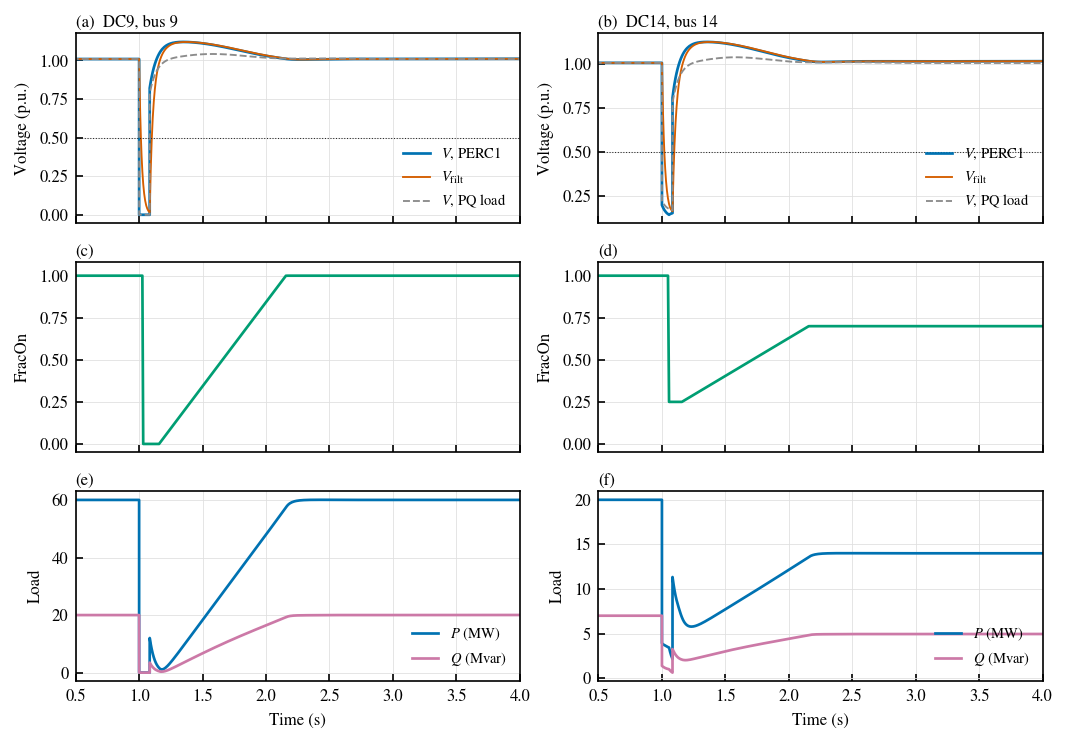

Fig. 3.  IEEE 14-bus system, three-phase fault at bus 9 (1.0 s, 5 cycles). Bus voltage with PERC1 and with PQ loads, model voltage Vfilt, FracOn and load power of the two data centers. Dotted: Vcease.


In [14]:
# Fig. 3: fault at bus 9
fig, axs = plt.subplots(3, 2, figsize=(W2, 5.0), sharex=True)
tb = np.array(sb.dae.ts.t)
for j, name in enumerate(DCS):
    bus = sa.Bus.idx2uid(m.bus.v[j])
    ax = axs[0, j]
    ax.plot(t, rec(sa, sa.Bus.v, bus), color=C_BLUE, label='$V$, PERC1')
    ax.plot(t, rec(sa, m.Vfilt, j), color=C_ORANGE, lw=0.9, label='$V_\\mathrm{filt}$')
    ax.plot(tb, rec(sb, sb.Bus.v, bus), color=C_GREY, lw=0.9, ls='--', label='$V$, PQ load')
    ax.axhline(m.Vcease.v[j], color=C_INK, lw=0.5, ls=':')
    ax.set_ylabel('Voltage (p.u.)')
    ax.legend(loc='lower right')
    panel(ax, 'ab'[j], f'{name}, bus {int(m.bus.v[j])}')
    ax = axs[1, j]
    ax.plot(t, rec(sa, m.FracOn, j), color=C_GREEN)
    ax.set_ylabel('FracOn')
    ax.set_ylim(-0.05, 1.08)
    panel(ax, 'cd'[j])
    ax = axs[2, j]
    ax.plot(t, rec(sa, m.Pmw, j), color=C_BLUE, label='$P$ (MW)')
    ax.plot(t, rec(sa, m.Qmvar, j), color=C_MAG, label='$Q$ (Mvar)')
    ax.set_ylabel('Load')
    ax.set_xlabel('Time (s)')
    ax.legend(loc='lower right')
    panel(ax, 'ef'[j])
axs[0, 0].set_xlim(0.5, 4.0)
plt.tight_layout()
plt.show()
print('Fig. 3.  IEEE 14-bus system, three-phase fault at bus 9 (1.0 s, 5 cycles). Bus voltage with PERC1 and '
      'with PQ loads, model voltage Vfilt, FracOn and load power of the two data centers. Dotted: Vcease.')

[PASS] C4   generator trip: droop reduces the load, P = MWinit + MBase x Kdroop x deadband(wfilt)
            wfilt -0.342 Hz at 20 s; P 59.221 MW (expected 59.221); without droop 60.000 MW


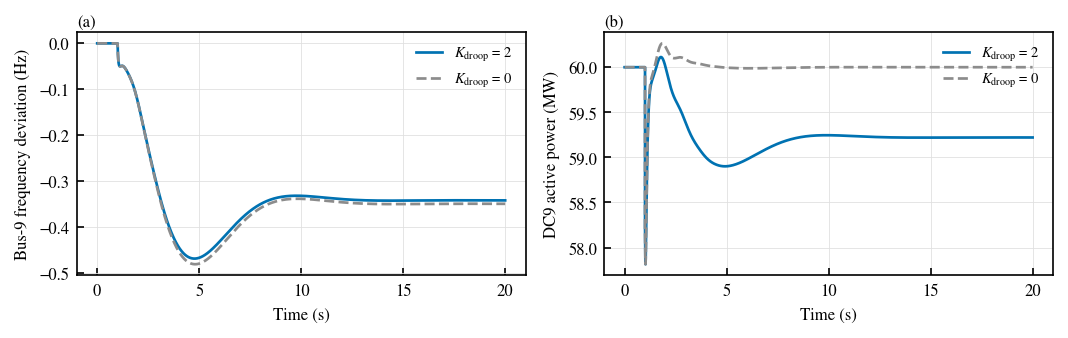

Fig. 4.  IEEE 14-bus system, trip of the generator at bus 2 (40 MW) at 1.0 s, with and without the frequency droop of DC9.


In [15]:
# C4: generator trip. DC9 has a frequency droop Kdroop = 2 with a +-0.0005 pu deadband.
sd = run_ieee14(CASE_TRIP, 20.0, trip=True)
s0 = run_ieee14(CASE_TRIP, 20.0, trip=True, prm={'DC9': dict(Kdroop=0.0)})
m = sd.PERC1
w_end = rec(sd, m.wfilt, 0)[-1]
db = w_end - m.Dbfl.v[0] if w_end < m.Dbfl.v[0] else (w_end - m.Dbfh.v[0] if w_end > m.Dbfh.v[0] else 0.0)
P_exp = 60.0 + m.MB.v[0] * m.Kdroop.v[0] * db  # steady state, nP = 0: P = MWinit + MBase Kdroop DB(wfilt)
P_end, P_end0 = rec(sd, m.Pmw, 0)[-1], rec(s0, s0.PERC1.Pmw, 0)[-1]
check(
    'C4',
    'generator trip: droop reduces the load, P = MWinit + MBase x Kdroop x deadband(wfilt)',
    sd.exit_code == 0 and abs(P_end - P_exp) < 5e-3 and P_end < 60.0 and abs(P_end0 - 60.0) < 5e-3,
    f'wfilt {w_end * FN:+.3f} Hz at 20 s; P {P_end:.3f} MW (expected {P_exp:.3f}); without droop {P_end0:.3f} MW',
)

# Fig. 4
fig, axs = plt.subplots(1, 2, figsize=(W2, 2.3))
bf = sd.BusFreq.idx2uid(m.busfreq.v[0])
for s, lab, c, ls in ((sd, '$K_\\mathrm{droop}$ = 2', C_BLUE, '-'), (s0, '$K_\\mathrm{droop}$ = 0', C_GREY, '--')):
    ts = np.array(s.dae.ts.t)
    axs[0].plot(ts, (rec(s, s.BusFreq.f, bf) - 1) * FN, color=c, ls=ls, label=lab)
    axs[1].plot(ts, rec(s, s.PERC1.Pmw, 0), color=c, ls=ls, label=lab)
axs[0].set_ylabel('Bus-9 frequency deviation (Hz)')
axs[1].set_ylabel('DC9 active power (MW)')
for ax, tag in zip(axs, 'ab'):
    ax.set_xlabel('Time (s)')
    ax.legend(loc='upper right')
    panel(ax, tag)
plt.tight_layout()
plt.show()
print('Fig. 4.  IEEE 14-bus system, trip of the generator at bus 2 (40 MW) at 1.0 s, with and without the '
      'frequency droop of DC9.')

## 5 Summary

In [16]:
CK = pd.DataFrame(CHECKS)
for row in CK.itertuples():
    print(f"{row.id:<4} {'PASS' if row.passed else 'FAIL'}  {row.description}")
print(f'\n{int(CK.passed.sum())} of {len(CK)} checks passed')
assert CK.passed.all()

A1   PASS  FracOn example: two dips and one dip shorter than Tcease
A2   PASS  recovery during Tdelay: the cease is not cancelled
A3   PASS  Trecon interrupted: voltage between Vcease and Vrecon restarts the timer
A4   PASS  dip during the ramp: FracOn frozen during Tdelay, then ceased again
A4a  PASS  ramp continues during Tcease and is frozen at its value when Tdelay starts
A4b  PASS  Tdelay expires: Ramp -> Ceased directly, FracOn = 1 - Fcease
A5   PASS  Tramp = 0: jump without Ramp mode; Frecon > 1: final FracOn > 1; Fcease = 0: logic off
A6   PASS  300 random parameter sets and voltage profiles: model function equals the reference at every step
B1   PASS  initialization: P, Q = power-flow load; MBase = P0 / Lfm; Ip = Lfm / V0; Iqextra carries Q0 - QPratio P0
B2   PASS  device response equals the reference in all six scenarios
B3   PASS  current limits: Ipv = Ipmax and Iqv = Iqmax during the 0.75 pu dip
C1   PASS  IEEE-14 initialization: both PQ loads taken over at their power-flow